# Business Scenario 

A university received 17,339 applications across three colleges: Business & Economics, Math & Science, and Arts & Letters. The university's admissions office wants to understand differences in application volumes, academic performance, and admission outcomes across colleges. As a Business Data Analyst, your task is to analyze the admissions data, identify meaningful patterns, and recommend strategies to improve admission and enrollment planning.
  
<b>Dataset Description</b>
* Applicant: Unique applicant identification number.
* Sex: Applicant's sex (M/F).
* SAT_ACT: Standardized admission test score.
* College: College to which the applicant applied.
* Admitted: Whether admission was offered (Yes/No).
* Enrolled: Whether the applicant enrolled (Yes/No).
* Extracurricular_Hours: Weekly hours spent on extracurricular activities.

<b>Assigned Tasks</b>

<i>Create each visualization using all three Python libraries (Matplotlib, Seaborn, and Plotly).</i>
* Task 01: Bar Plot - Compare the number of applications received by each college. Which college attracts the most applicants?
* Task 02: Histogram - Visualize the distribution of SAT_ACT scores. What is the most common score range?
* Task 03: Box Plot - Compare SAT_ACT scores across the three colleges. Which college has the highest median score?
* Task 04: Data-Driven Insights - Identify three important findings and recommend strategies to improve admission and enrollment planning.
* Task 05: GitHub Submission - Push your Python code and visualizations to a GitHub repository and share the repository link.

<b>Intended Learning Outcome</b>

Apply Matplotlib, Seaborn, and Plotly to visualize university admissions data, identify patterns, and support data-driven decision-making.

# Environment Setup & Data Preparation 
* Import Pandas, NumPy, Matplotlib, Seaborn, and Plotly Libraries
* Read 'applications.xlsx' into dataframe
* Audit for null entries & produce cleaned dataframe

In [1]:
## Import libraries for the requirement:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Read Excel file 'applications.xlsx' into a dataframe
df = pd.read_excel('applications.xlsx')

len(df)  ## Output: 17339


17339

In [2]:
# Review data configuration 
print(df.head()) 

   Applicant Sex  SAT_ACT               College Admitted Enrolled  \
0          1   M     1460  Business & Economics      Yes       No   
1          2   F     1180        Math & Science       No       No   
2          3   M     1340        Arts & Letters      Yes       No   
3          4   M     1190  Business & Economics       No       No   
4          5   F     1290  Business & Economics       No       No   

   Extracurricular_Hours  
0                      5  
1                     10  
2                      7  
3                      1  
4                      4  


In [3]:
# Identify null values
print(df.isnull().sum())  ## Output: No missing values found

Applicant                0
Sex                      0
SAT_ACT                  0
College                  0
Admitted                 0
Enrolled                 0
Extracurricular_Hours    0
dtype: int64


In [4]:
# Additional "null insurance" specifically for applicants and college.
df1 = df.dropna(subset = ['Applicant', 'College'])

# Confirm df is sanitized. 
print(df1.head())  ## Output confirms clean and unchanged dataframe

len(df1)  ## Expected output = 17339 -- confirmed

   Applicant Sex  SAT_ACT               College Admitted Enrolled  \
0          1   M     1460  Business & Economics      Yes       No   
1          2   F     1180        Math & Science       No       No   
2          3   M     1340        Arts & Letters      Yes       No   
3          4   M     1190  Business & Economics       No       No   
4          5   F     1290  Business & Economics       No       No   

   Extracurricular_Hours  
0                      5  
1                     10  
2                      7  
3                      1  
4                      4  


17339

# Task 01: Bar Plot
* Compare the number of applications received by each college.
* Which college attracts the most applicants?

College
Arts & Letters          6964
Business & Economics    4103
Math & Science          6272
Name: Applicant, dtype: int64


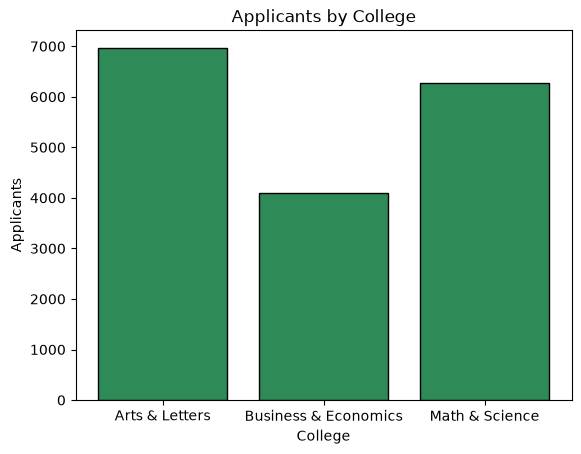

In [5]:
# Task 1.1 -- Bar Plot Using Matplotlib
## Working with cleaned df1 ('Applicant' and 'College')

app_counts = df1.groupby('College')['Applicant'].count()

print(app_counts)  ## Output identifies college with most applicants at 6,964:  Arts & Letters

plt.bar(app_counts.index, app_counts.values, 
        color = 'seagreen',
        edgecolor = 'black')

# Adding title and labels
plt.title("Applicants by College")
plt.xlabel("College")
plt.ylabel("Applicants")

# Display bar plot
plt.show()  ## Output confirms table of count values printed above (A&L just under 7,000)

College
Arts & Letters          6964
Math & Science          6272
Business & Economics    4103
Name: count, dtype: int64


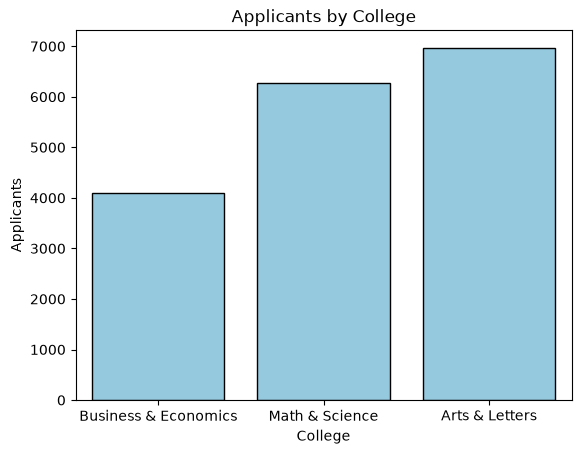

In [6]:
# Task 1.2 -- Bar Plot Using Seaborn

print(df1['College'].value_counts())  ## Confirms A&L with highest appliant count at 6,964 applications.

# Create bar plot, this time using sns.countplot() to obtain values directly from df1 dataframe.
sns.countplot(data = df1, 
              x = 'College', 
              color = 'skyblue',
              edgecolor = 'black')

# Add title and axis labels
plt.title("Applicants by College")
plt.xlabel("College")
plt.ylabel("Applicants")

# Display bar plot 
plt.show()  ## Output again confirms Arts & Letters with most applicants.

                College  Applicant
0        Arts & Letters       6964
1  Business & Economics       4103
2        Math & Science       6272


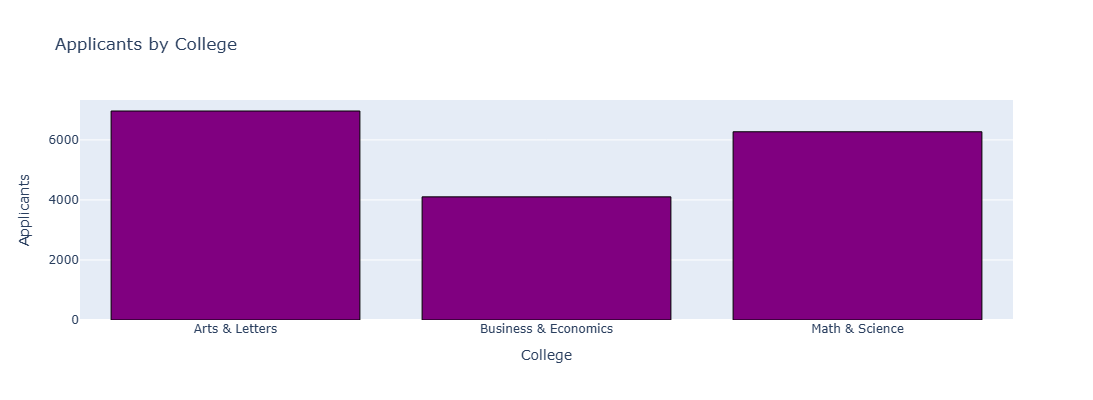

In [7]:
# Task 1.3 -- Bar Plot Using Plotly

# Calculate applications per college
app_counts = df1.groupby('College', as_index = False)['Applicant'].count()

# Display table of count values
print(app_counts)

# Create interactive bar plot
fig = px.bar(app_counts, x = 'College', y = 'Applicant',
             color_discrete_sequence = ['purple'],
             title = "Applicants by College",)

# Add bar outlines and axis labels
fig.update_traces(marker_line_color = 'black', marker_line_width = 1)
fig.update_layout(
    xaxis_title = "College",
    yaxis_title = "Applicants",
    width = 600,
    height = 400
)

# Display bar plot
fig.show()  ## Output again indicates Arts & Letters as college with most applicants at 6964

# Task 02: Histogram
* Visualize the distribution of SAT_ACT scores.
* What is the most common score range?

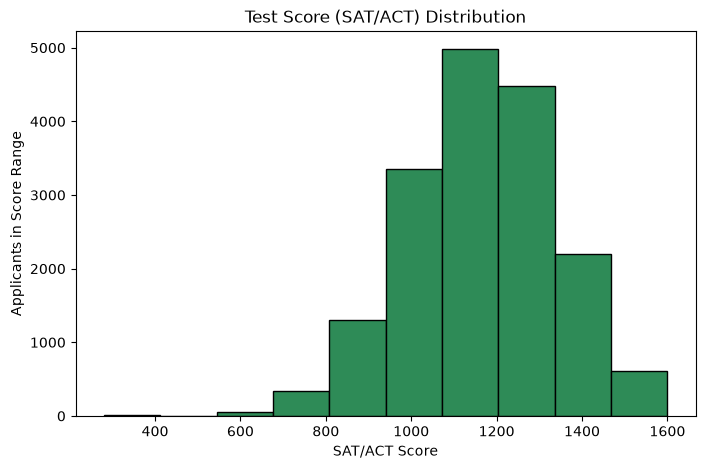

In [8]:
# Task 2.1 -- Histogram Using Matplotlib

# Set figure size
plt.figure(figsize = (8,5))

# Create histogram
plt.hist(df1['SAT_ACT'], 
         bins = 10, 
         color = 'seagreen',
         edgecolor = 'black')

# Add title and axis labels
plt.title("Test Score (SAT/ACT) Distribution")
plt.xlabel("SAT/ACT Score")
plt.ylabel("Applicants in Score Range")

# Display Histogram
plt.show()  ## Most common score range: ~1,070 to ~1,200 points

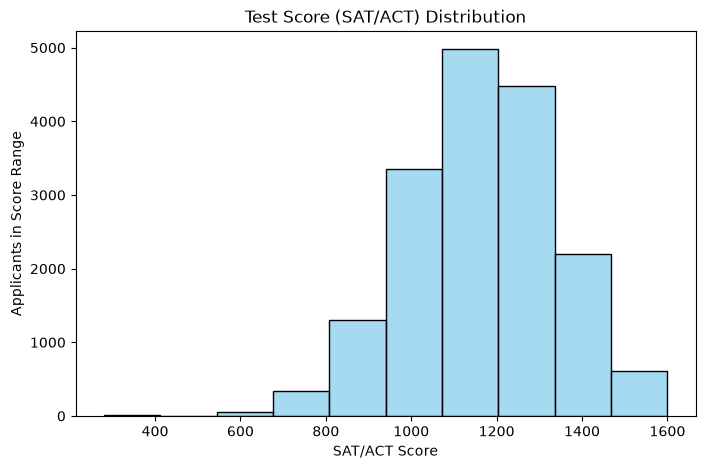

In [9]:
# Task 2.2 -- Histogram Using Seaborn

# Set figure size
plt.figure(figsize = (8,5))

# Create histogram
sns.histplot(data = df1, x = 'SAT_ACT', bins = 10, color = 'skyblue')

# Add title and axis labels
plt.title("Test Score (SAT/ACT) Distribution")
plt.xlabel("SAT/ACT Score")
plt.ylabel("Applicants in Score Range")

# Display histogram
plt.show()

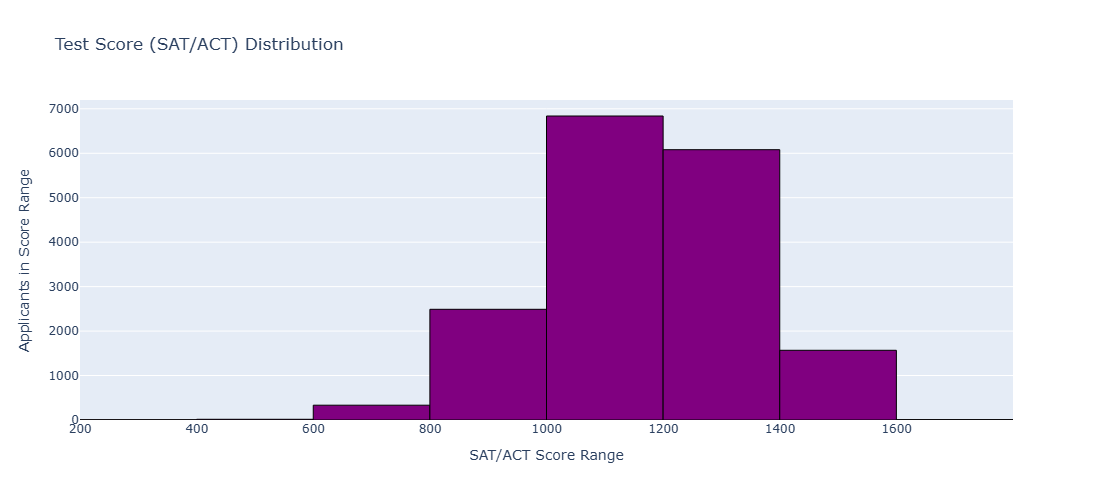

In [10]:
# Task 2.3 -- Histogram Using Plotly

# Create histogram
fig = px.histogram(
    df1,
    x = 'SAT_ACT',
    nbins = 10,
    color_discrete_sequence = ['purple'],
    title = "Test Score (SAT/ACT) Distribution",
    width = 800,
    height = 500
)

# Add bar outlines and axis labels
fig.update_traces(marker_line_color = 'black', marker_line_width = 1)
fig.update_layout(
    xaxis_title = "SAT/ACT Score Range",
    yaxis_title = "Applicants in Score Range"
)

# Display histogram
fig.show()  ## Output shows most students (6,838) are in the 1,000 to 1,190 test score range.

# Task 03: Scatter Plot 
* Visualize the relationship between SAT_ACT scores and Extracurricular_Hours. 
* Is there a positive, negative, or no clear relationship?

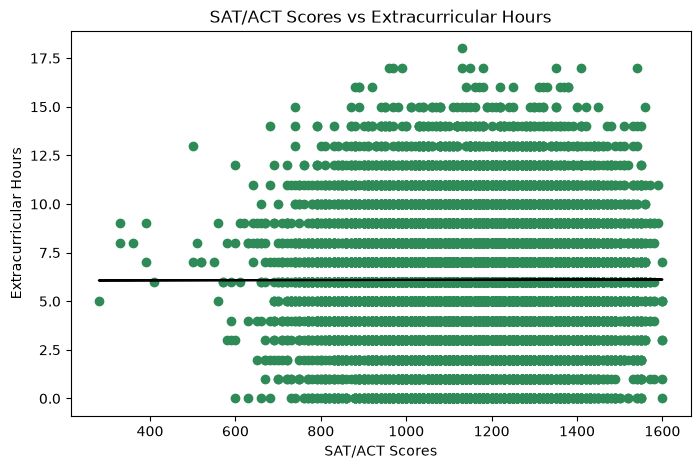

In [11]:
# Task 3.1 -- Scatter Plot Using Matplotlib

# Create a scatter plot
plt.figure(figsize = (8,5))
plt.scatter(df1['SAT_ACT'], df1['Extracurricular_Hours'], color = 'seagreen')

# Add trendline
m, b = np.polyfit(df1['SAT_ACT'], df1['Extracurricular_Hours'], 1)
plt.plot(df1['SAT_ACT'], m * df1['SAT_ACT'] + b, color = 'black')

# Add title and axis labels
plt.title("SAT/ACT Scores vs Extracurricular Hours")
plt.xlabel("SAT/ACT Scores")
plt.ylabel("Extracurricular Hours")

# Display scatter plot
plt.show()  ## This plot shows that there is no clear relationship between extracurricular hours and test scores.

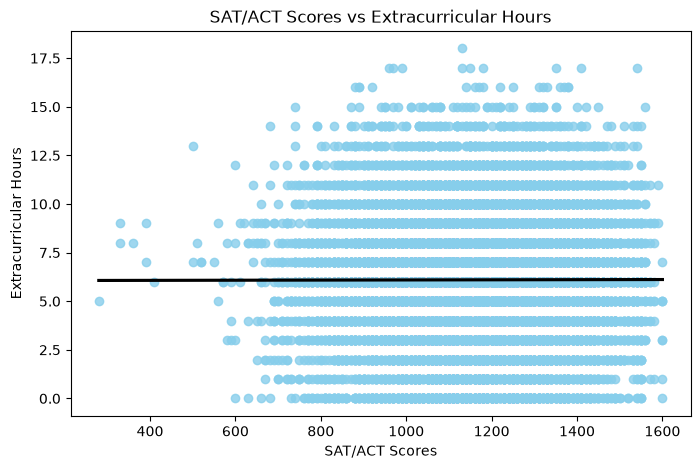

In [12]:
# Task 3.2 -- Scatter Plot Using Seaborn

# Create scatter plot with trendline
plt.figure(figsize = (8,5))
sns.regplot(data = df1, x = 'SAT_ACT', y = 'Extracurricular_Hours',
            scatter_kws = {'color': 'skyblue'},
            line_kws = {'color': 'black'},
            ci = None
           )

# Add title and axis labels
plt.title("SAT/ACT Scores vs Extracurricular Hours")
plt.xlabel("SAT/ACT Scores")
plt.ylabel("Extracurricular Hours")

# Display scatter plot
plt.show()  ## This plot again shows no clear relationship.

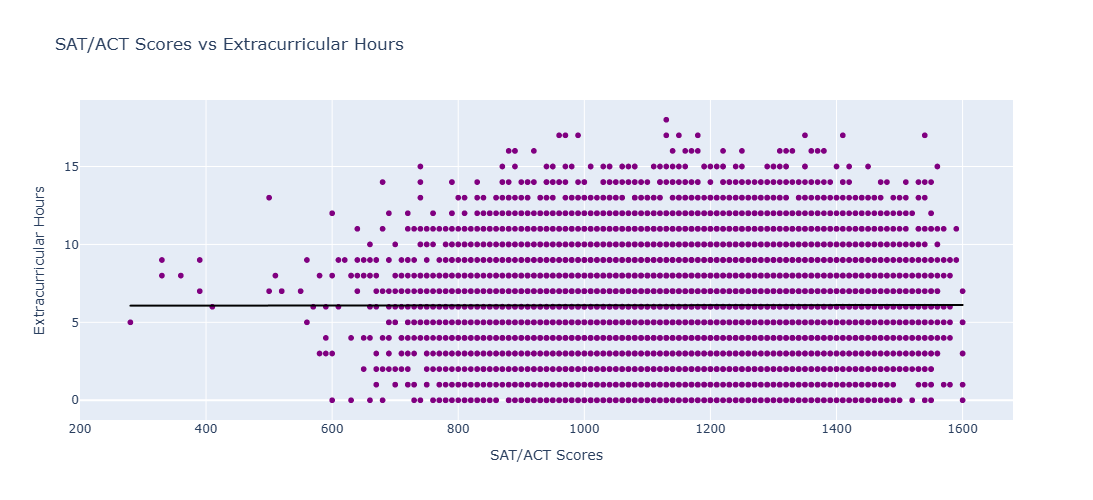

In [13]:
# Task 3.3 -- Scatter Plot Using Plotly

# Create scatter plot with trendline
fig = px.scatter(
    df,
    x = 'SAT_ACT',
    y = 'Extracurricular_Hours',
    trendline = 'ols',
    trendline_color_override = 'black',
    color_discrete_sequence = ['purple'],
    title = "SAT/ACT Scores vs Extracurricular Hours",
    width = 800,
    height = 500
)

# Add axis labels
fig.update_layout(
    xaxis_title = "SAT/ACT Scores",
    yaxis_title = "Extracurricular Hours"
)

# Show scatter plot
fig.show()  

# Task 04: Data-Driven Insights
* Identify three important findings.
* Recommend strategies to improve admission and enrollment planning.

# Key Findings & Recommendations:
<b>1. From the bar plots in Task 01:</b> Arts & Letters attracts ~40% (6,964) of all applicants (17,339), with Math & Sciences coming in at a close second receiving ~36% of applications (6,272), and Business & Economics coming in last attracting ~24% of applicants (4,103).

<b>Recommendation:</b> Because Business & Economics sees roughly 41% fewer applicants than Arts & Letters, admissions teams should audit outreach pipelines to ensure an optimal mix of effort, expand lower-cost digital recruitment efforts, and highlight career placement outcomes to grow Business & Economics volume without cannibalizing the other two colleges.

<b>2. From the histograms in Task 02:</b> SAT/ACT score distributions display slight left (negative) skewness but are otherwise roughly normal and with the largest concentration of applicants (6,838) scoring between 1,000 and 1,190 points comprising ~39.4% of the entire pool.

<b>Recommendation:</b> As the bulk of incoming applicants cluster in the 1,000 to 1,190 SAT/ACT score range, enrollment planners can forecast introductory course demand and allocate faculty, tutoring, and merit-aid around this central cohort while reserving targeted support resources for the smaller tail of applicants scoring below 800 points.

<b>3. From the scatter plots in Task 03:</b> The flat linear trendline (averaging roughly 6 hours per week across all test score levels) indicates no clear linear correlation between SAT/ACT scores and number of reported extracurricular hours. This shows that high-scoring and lower-scoring applicants participate in extracurricular activities at similar rates.

<b>Recommendation:</b> Given the absence of linear tradeoff between SAT/ACT scores and reported extracurricular hours, admissions committees should avoid using one metric as a proxy for the other. Instead, they should score academic readiness and extracurricular leadership based on independent rubrics to avoid overlooking notably well-rounded applicants.